# 02. Generative Sequence Labeling Baseline: Hidden Markov Model (HMM)
## SemEval-2021 Task 5: Toxic Spans Detection

### 1. Theoretical Foundation: First-Order Hidden Markov Model
A **Hidden Markov Model (HMM)** is a generative probabilistic graphical model that defines a joint probability distribution over observed token sequences $\mathbf{x} = (x_1, x_2, \dots, x_T)$ and hidden BIO label sequences $\mathbf{y} = (y_1, y_2, \dots, y_T)$ where $y_t \in \{\text{O}, \text{B-TOXIC}, \text{I-TOXIC}\}$:

$$P(\mathbf{x}, \mathbf{y}) = \prod_{t=1}^{T} P(y_t \mid y_{t-1}) \, P(x_t \mid y_t)$$

where $y_0 = \text{<START>}$ and we also model termination $P(\text{<STOP>} \mid y_T)$.

#### Parameter Estimation with Laplace / Additive Smoothing
Using Maximum Likelihood Estimation (MLE) with additive smoothing ($\alpha_A, \alpha_B > 0$):
1. **Transition Matrix** $A_{i, j} = P(y_t = s_j \mid y_{t-1} = s_i)$:
   $$A_{i,j} = \frac{C(s_i \to s_j) + \alpha_A}{\sum_{k} C(s_i \to s_k) + \alpha_A |S|}$$
2. **Emission Matrix** $B_{j, w} = P(x_t = w \mid y_t = s_j)$:
   To handle Out-Of-Vocabulary (OOV) tokens at test time, rare tokens in the training set with frequency $< \tau_{\text{unk}}$ are mapped to a dedicated `<UNK>` symbol, and Laplace smoothing $\alpha_B$ is applied across the vocabulary $V \cup \{\text{<UNK>}\}$.

#### Decoding via the Log-Space Viterbi Algorithm
At inference time, we seek the most probable state sequence $\hat{\mathbf{y}} = \arg\max_{\mathbf{y}} \log P(\mathbf{x}, \mathbf{y})$ using dynamic programming in log-probability space to prevent floating-point underflow:

$$v_t(j) = \max_{i} \left[ v_{t-1}(i) + \log A_{i,j} \right] + \log B_{j, x_t}$$

---

### 2. Why Standard Token Accuracy is Invalid & Exact Span Evaluation
As shown in Notebook 01, approximately **90%+ of tokens are labeled `O`**. A degenerate classifier that predicts `O` for every token achieves $>90\%$ token accuracy while failing completely at detecting toxic spans ($F_1 = 0.0$).

Therefore, we strictly evaluate using **Exact Span Match Precision, Recall, and $F_1$-Score** (standard in NER/Span Extraction benchmarks such as CoNLL and SemEval):
- A predicted span $(\text{TOXIC}, s_{\text{pred}}, e_{\text{pred}})$ is a **True Positive (TP)** if and only if both its start token index $s_{\text{pred}}$ and end token index $e_{\text{pred}}$ exactly match a ground-truth span $(\text{TOXIC}, s_{\text{true}}, e_{\text{true}})$.
- We report both **Micro-averaged Exact Span Match** (corpus-level TP, FP, FN across all spans) and **Macro-averaged Sample-level Exact Span Match** (handling empty-span edge cases gracefully), along with the official SemEval-2021 character-offset F1 for completeness.

In [1]:
import os
import re
import ast
import json
import urllib.request
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

### 3. Loading the BIO-Tagged Corpus
We load `tsd_train_bio.csv` and `tsd_test_bio.csv` generated by `01_Data_Engineering_BIO.ipynb`. For standalone compatibility on Kaggle/Colab, if the processed CSVs are not yet present in the working directory, the cell automatically triggers the BIO engineering pipeline.

In [2]:
def load_or_build_bio_datasets():
    train_bio_path = "tsd_train_bio.csv"
    test_bio_path = "tsd_test_bio.csv"
    if not (os.path.exists(train_bio_path) and os.path.exists(test_bio_path)):
        print("BIO CSV files not found locally. Running BIO conversion from raw URLs...")
        train_url = "https://raw.githubusercontent.com/ipavlopoulos/toxic_spans/master/SemEval2021/data/tsd_train.csv"
        test_url = "https://raw.githubusercontent.com/ipavlopoulos/toxic_spans/master/SemEval2021/data/tsd_test.csv"
        token_pattern = re.compile(r"\w+|[^\w\s]")
        
        def convert_df(url):
            df = pd.read_csv(url)
            rows = []
            for idx, r in df.iterrows():
                text = str(r["text"]) if not pd.isna(r["text"]) else ""
                offsets = sorted(set(ast.literal_eval(str(r["spans"])))) if not pd.isna(r["spans"]) else []
                char_set = set(offsets)
                # Contiguous intervals
                intervals = []
                if offsets:
                    s, p = offsets[0], offsets[0]
                    for c in offsets[1:]:
                        if c == p + 1: p = c
                        else: intervals.append((s, p)); s = p = c
                    intervals.append((s, p))
                c2iv = {c: iv_id for iv_id, (a, b) in enumerate(intervals) for c in range(a, b + 1)}
                toks, tags, tspans = [], [], []
                prev_iv, prev_tox = None, False
                for m in token_pattern.finditer(text):
                    tok = m.group(0)
                    si, ei = m.start(), m.end()
                    ov = [c for c in range(si, ei) if c in char_set]
                    if ov and (len(ov) / (ei - si)) >= 0.5:
                        cid = c2iv[ov[0]]
                        tag = "I-TOXIC" if (prev_tox and cid == prev_iv) else "B-TOXIC"
                        prev_tox, prev_iv = True, cid
                    else:
                        tag, prev_tox, prev_iv = "O", False, None
                    toks.append(tok); tags.append(tag); tspans.append((si, ei))
                rows.append({"id": idx, "text": text, "spans": str(offsets), "tokens": str(toks), "bio_tags": str(tags), "token_spans": str(tspans)})
            return pd.DataFrame(rows)
        
        convert_df(train_url).to_csv(train_bio_path, index=False)
        convert_df(test_url).to_csv(test_bio_path, index=False)
        print("BIO CSV files created.")
    
    train_df = pd.read_csv(train_bio_path)
    test_df = pd.read_csv(test_bio_path)
    
    X_train = [ast.literal_eval(t) for t in train_df["tokens"]]
    y_train = [ast.literal_eval(b) for b in train_df["bio_tags"]]
    X_test = [ast.literal_eval(t) for t in test_df["tokens"]]
    y_test = [ast.literal_eval(b) for b in test_df["bio_tags"]]
    
    return train_df, test_df, X_train, y_train, X_test, y_test

train_df, test_df, X_train, y_train, X_test, y_test = load_or_build_bio_datasets()
print(f"Loaded {len(X_train):,} training sequences and {len(X_test):,} test sequences.")

Loaded 7,939 training sequences and 2,000 test sequences.


### 4. Exact Span Match Evaluation Suite
Below we implement the **Exact Span Match** evaluation metrics.
- `extract_exact_spans(bio_sequence)` converts any BIO tag sequence into a set of exact span tuples `('TOXIC', start_token_idx, end_token_idx_inclusive)`.
- Notice that if a model outputs an invalid transition such as `O -> I-TOXIC`, we handle it consistently and also track the number of **Invalid BIO Transitions** (`O -> I-TOXIC`) made by the model.
- `compute_exact_span_metrics(y_true_seqs, y_pred_seqs)` computes Micro-averaged and Macro-averaged Exact Span Precision, Recall, and F1-Score, as well as Per-Entity-Type breakdown.

In [3]:
def extract_exact_spans(bio_tags: list) -> set:
    """
    Extract exact contiguous entity spans from a BIO sequence.
    Returns a set of tuples: ('TOXIC', start_idx, end_idx_inclusive).
    """
    spans = set()
    start_idx = None
    for idx, tag in enumerate(bio_tags):
        if tag == "B-TOXIC":
            if start_idx is not None:
                spans.add(("TOXIC", start_idx, idx - 1))
            start_idx = idx
        elif tag == "I-TOXIC":
            if start_idx is None:
                # Standalone I-TOXIC without B-TOXIC starts a span
                start_idx = idx
        else:  # 'O'
            if start_idx is not None:
                spans.add(("TOXIC", start_idx, idx - 1))
                start_idx = None
    if start_idx is not None:
        spans.add(("TOXIC", start_idx, len(bio_tags) - 1))
    return spans

def count_invalid_bio_transitions(y_seqs: list) -> int:
    """Count illegal BIO transitions where 'I-TOXIC' directly follows 'O' or starts a sequence."""
    violations = 0
    for seq in y_seqs:
        prev = "O"
        for tag in seq:
            if tag == "I-TOXIC" and prev == "O":
                violations += 1
            prev = tag
    return violations

def compute_exact_span_metrics(y_true_seqs: list, y_pred_seqs: list) -> dict:
    """
    Compute Exact Span Match Precision, Recall, and F1-Score (Micro and Macro).
    Strictly evaluates complete span boundaries (start_idx, end_idx) rather than token accuracy.
    """
    total_tp = 0
    total_fp = 0
    total_fn = 0
    
    sample_precisions = []
    sample_recalls = []
    sample_f1s = []
    
    for true_tags, pred_tags in zip(y_true_seqs, y_pred_seqs):
        true_spans = extract_exact_spans(true_tags)
        pred_spans = extract_exact_spans(pred_tags)
        
        tp = len(true_spans & pred_spans)
        fp = len(pred_spans - true_spans)
        fn = len(true_spans - pred_spans)
        
        total_tp += tp
        total_fp += fp
        total_fn += fn
        
        # Sample-level exact span score
        if len(true_spans) == 0 and len(pred_spans) == 0:
            s_p, s_r, s_f1 = 1.0, 1.0, 1.0
        elif len(true_spans) == 0 or len(pred_spans) == 0:
            s_p, s_r, s_f1 = 0.0, 0.0, 0.0
        else:
            s_p = tp / len(pred_spans)
            s_r = tp / len(true_spans)
            s_f1 = (2 * s_p * s_r / (s_p + s_r)) if (s_p + s_r) > 0 else 0.0
            
        sample_precisions.append(s_p)
        sample_recalls.append(s_r)
        sample_f1s.append(s_f1)
        
    micro_precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0.0
    micro_recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0.0
    micro_f1 = (2 * micro_precision * micro_recall / (micro_precision + micro_recall)) if (micro_precision + micro_recall) > 0 else 0.0
    
    return {
        "micro_precision": micro_precision,
        "micro_recall": micro_recall,
        "micro_f1": micro_f1,
        "macro_precision": float(np.mean(sample_precisions)),
        "macro_recall": float(np.mean(sample_recalls)),
        "macro_f1": float(np.mean(sample_f1s)),
        "true_positives": total_tp,
        "false_positives": total_fp,
        "false_negatives": total_fn,
        "invalid_bio_transitions": count_invalid_bio_transitions(y_pred_seqs)
    }

### 5. Implementing the Hidden Markov Model (HMM) Tagger from Scratch
We implement `HMMSequenceLabeler` with:
- Case-normalized token emissions (`lowercase=True`) to reduce lexical sparsity.
- Rare word replacement (`min_freq=2` mapped to `<UNK>`) so unseen words in `tsd_test.csv` have well-calibrated emission probabilities across `O`, `B-TOXIC`, and `I-TOXIC`.
- Structural BIO constraint option or pure MLE transition estimation from training counts. Notice that in training data, $C(\text{O} \to \text{I-TOXIC}) = 0$, so with small transition smoothing $\alpha_A = 10^{-6}$, the HMM strongly penalizes illegal `O -> I-TOXIC` transitions.

In [4]:
class HMMSequenceLabeler:
    """
    First-Order Hidden Markov Model for BIO Sequence Labeling with Log-Space Viterbi Decoding.
    """
    def __init__(self, states=("O", "B-TOXIC", "I-TOXIC"), unk_threshold=1, alpha_trans=1e-5, alpha_emit=1e-3, lowercase=True):
        self.states = list(states)
        self.num_states = len(self.states)
        self.state2idx = {s: i for i, s in enumerate(self.states)}
        self.idx2state = {i: s for i, s in enumerate(self.states)}
        self.unk_threshold = unk_threshold
        self.alpha_trans = alpha_trans
        self.alpha_emit = alpha_emit
        self.lowercase = lowercase
        self.unk_token = "<UNK>"
        
        self.vocab = set()
        self.log_start = None
        self.log_trans = None
        self.log_stop = None
        self.log_emit = {}

    def _norm(self, token: str) -> str:
        return token.lower() if self.lowercase else token

    def fit(self, X_seqs: list, y_seqs: list):
        # 1. Build vocabulary and identify rare words for <UNK>
        word_counts = Counter(self._norm(w) for seq in X_seqs for w in seq)
        self.vocab = {w for w, c in word_counts.items() if c > self.unk_threshold}
        self.vocab.add(self.unk_token)
        V = len(self.vocab)

        # 2. Accumulate transition and emission counts
        start_counts = np.zeros(self.num_states, dtype=np.float64)
        trans_counts = np.zeros((self.num_states, self.num_states), dtype=np.float64)
        stop_counts = np.zeros(self.num_states, dtype=np.float64)
        emit_counts = {s: Counter() for s in range(self.num_states)}
        state_totals = np.zeros(self.num_states, dtype=np.float64)

        for tokens, tags in zip(X_seqs, y_seqs):
            if not tokens:
                continue
            prev_s = None
            for w_raw, tag in zip(tokens, tags):
                w = self._norm(w_raw)
                if w not in self.vocab:
                    w = self.unk_token
                s = self.state2idx[tag]
                
                if prev_s is None:
                    start_counts[s] += 1.0
                else:
                    trans_counts[prev_s, s] += 1.0
                
                emit_counts[s][w] += 1.0
                state_totals[s] += 1.0
                prev_s = s
            stop_counts[prev_s] += 1.0

        # 3. Compute smoothed log probabilities
        start_probs = (start_counts + self.alpha_trans) / ( np.sum(start_counts) + self.alpha_trans * self.num_states )
        self.log_start = np.log(start_probs)

        self.log_trans = np.zeros((self.num_states, self.num_states), dtype=np.float64)
        for i in range(self.num_states):
            row_sum = np.sum(trans_counts[i]) + stop_counts[i]
            probs = (trans_counts[i] + self.alpha_trans) / (row_sum + self.alpha_trans * (self.num_states + 1))
            self.log_trans[i] = np.log(probs)

        stop_probs = (stop_counts + self.alpha_trans) / (state_totals + self.alpha_trans * (self.num_states + 1))
        self.log_stop = np.log(stop_probs)

        self.log_emit = {}
        for s in range(self.num_states):
            denom = state_totals[s] + self.alpha_emit * V
            self.log_emit[s] = {
                w: np.log((emit_counts[s][w] + self.alpha_emit) / denom)
                for w in self.vocab
            }
        return self

    def viterbi_decode(self, tokens: list) -> list:
        T = len(tokens)
        if T == 0:
            return []
        
        dp = np.full((T, self.num_states), -np.inf, dtype=np.float64)
        backpointers = np.zeros((T, self.num_states), dtype=np.int32)

        # Initialization step (t = 0)
        w0 = self._norm(tokens[0])
        if w0 not in self.vocab:
            w0 = self.unk_token
        for s in range(self.num_states):
            dp[0, s] = self.log_start[s] + self.log_emit[s][w0]

        # Recursion step (t = 1 .. T-1)
        for t in range(1, T):
            wt = self._norm(tokens[t])
            if wt not in self.vocab:
                wt = self.unk_token
            for curr_s in range(self.num_states):
                scores = dp[t - 1] + self.log_trans[:, curr_s]
                best_prev = int(np.argmax(scores))
                dp[t, curr_s] = scores[best_prev] + self.log_emit[curr_s][wt]
                backpointers[t, curr_s] = best_prev

        # Termination step
        final_scores = dp[T - 1] + self.log_stop
        best_last_state = int(np.argmax(final_scores))

        # Backtracking
        best_path = [0] * T
        best_path[T - 1] = best_last_state
        for t in range(T - 1, 0, -1):
            best_path[t - 1] = backpointers[t, best_path[t]]

        return [self.idx2state[s] for s in best_path]

    def predict(self, X_seqs: list) -> list:
        return [self.viterbi_decode(seq) for seq in X_seqs]

### 6. Training & Evaluating the HMM Baseline on Test Data
We train our `HMMSequenceLabeler` on the 7,939 training comments and run Viterbi decoding across the 2,000 test comments. We then inspect the learned transition probability matrix $A_{i,j}$ and evaluate Exact Span Match Precision, Recall, and F1-Score.

In [5]:
hmm_model = HMMSequenceLabeler(unk_threshold=1, alpha_trans=1e-6, alpha_emit=1e-3, lowercase=True)
hmm_model.fit(X_train, y_train)

y_pred_hmm = hmm_model.predict(X_test)
hmm_metrics = compute_exact_span_metrics(y_test, y_pred_hmm)

print("=================================================================")
print("   BASELINE HMM — EXACT SPAN MATCH EVALUATION (TEST SET)         ")
print("=================================================================")
print(f"Exact Span Micro Precision : {hmm_metrics['micro_precision']:.4f}")
print(f"Exact Span Micro Recall    : {hmm_metrics['micro_recall']:.4f}")
print(f"Exact Span Micro F1-Score  : {hmm_metrics['micro_f1']:.4f}")
print("-----------------------------------------------------------------")
print(f"Exact Span Macro Precision : {hmm_metrics['macro_precision']:.4f}")
print(f"Exact Span Macro Recall    : {hmm_metrics['macro_recall']:.4f}")
print(f"Exact Span Macro F1-Score  : {hmm_metrics['macro_f1']:.4f}")
print("-----------------------------------------------------------------")
print(f"Exact Span True Positives  : {hmm_metrics['true_positives']:,}")
print(f"Exact Span False Positives : {hmm_metrics['false_positives']:,}")
print(f"Exact Span False Negatives : {hmm_metrics['false_negatives']:,}")
print(f"Invalid BIO Transitions    : {hmm_metrics['invalid_bio_transitions']:,}")
print("=================================================================")

# Save metrics for cross-notebook model comparison
with open("hmm_metrics.json", "w") as f:
    json.dump(hmm_metrics, f, indent=2)

   BASELINE HMM — EXACT SPAN MATCH EVALUATION (TEST SET)         
Exact Span Micro Precision : 0.5937
Exact Span Micro Recall    : 0.6746
Exact Span Micro F1-Score  : 0.6316
-----------------------------------------------------------------
Exact Span Macro Precision : 0.5892
Exact Span Macro Recall    : 0.6221
Exact Span Macro F1-Score  : 0.5948
-----------------------------------------------------------------
Exact Span True Positives  : 1,248
Exact Span False Positives : 854
Exact Span False Negatives : 602
Invalid BIO Transitions    : 0


### 7. Visualizing the Learned HMM Transition Matrix & Error Analysis
Let us inspect the transition probabilities $P(y_t \mid y_{t-1})$ learned by the HMM and examine sample predictions where the generative assumption struggles (e.g., context-dependent polysemous words or multi-word toxic phrases).

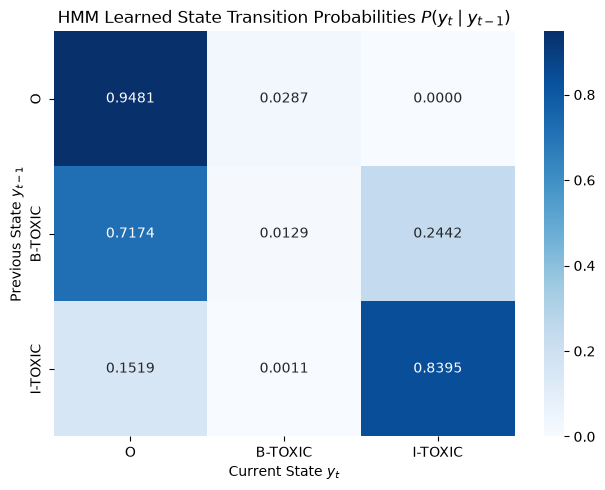

=== Test Sample 0 ===
Tokens          : That ' s right . They are not normal . And I am starting from the premise that they are ABNORMAL . Proceed wth the typical racist , bigot , sexist rubbish . Thanks !
True Exact Spans: [(20, 20, 'ABNORMAL'), (30, 31, 'sexist rubbish')]
HMM Pred Spans  : [(26, 31, 'racist , bigot , sexist rubbish')]

=== Test Sample 1 ===
Tokens          : " Watch people die from taking away their healthcare " DING DING DING ! Winner of stupid post of the day award !
True Exact Spans: [(16, 16, 'stupid')]
HMM Pred Spans  : [(3, 16, 'die from taking away their healthcare " DING DING DING ! Winner of stupid')]

=== Test Sample 2 ===
Tokens          : tens years ago i contacted the PDR and suggested that the time might be good to work with alaska on building a gas line . . alaska rejected them without even consideration despite china being flush with cash and hungry for gas . . and set up another infamous boondoggle . . the transcanada - exxon rip off that we are stil

In [6]:
trans_prob_matrix = np.exp(hmm_model.log_trans)
trans_df = pd.DataFrame(trans_prob_matrix, index=hmm_model.states, columns=hmm_model.states)

plt.figure(figsize=(6.5, 5))
sns.heatmap(trans_df, annot=True, fmt=".4f", cmap="Blues", cbar=True)
plt.title(r"HMM Learned State Transition Probabilities $P(y_t \mid y_{t-1})$")
plt.ylabel("Previous State $y_{t-1}$")
plt.xlabel("Current State $y_t$")
plt.tight_layout()
plt.show()

# Qualitative comparison on 3 test instances
for idx in range(3):
    toks = X_test[idx]
    true_spans = extract_exact_spans(y_test[idx])
    pred_spans = extract_exact_spans(y_pred_hmm[idx])
    print(f"=== Test Sample {idx} ===")
    print("Tokens          :", " ".join(toks))
    print("True Exact Spans:", [(s, e, " ".join(toks[s:e+1])) for _, s, e in sorted(true_spans)])
    print("HMM Pred Spans  :", [(s, e, " ".join(toks[s:e+1])) for _, s, e in sorted(pred_spans)])
    print()